# 🕸️ 03 · The PageRank Analogy: Solving a Recursive Definition

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 3 of 9
> Course notes: page 9, *"LLM: court, case, judgement … Recursive problem. PageRank: page is prestigious if other prestigious pages point at it. Assign influence = 1 ∀. Iteratively divide it equally across links. Under certain conditions you can always calculate prestige steady state. Same solution for this."*

The notes make a detour here, and it is worth following. Distributional semantics says:

> *the meaning of a word is defined by the meanings of the words around it.*

That definition is **recursive** – to know a word you must already know its neighbours, who need *their* neighbours, … The notes point out that the web had exactly the same problem, and that Google's **PageRank** solved it with a simple trick: **start with a guess and repeat the definition until nothing changes.** Word2vec will use the same strategy (repeat small updates until the vectors stop moving).

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | PageRank's recursive definition of prestige |
| 2 | Turning it into a matrix: $r\leftarrow Mr$ |
| 3 | Iterating to a **steady state**, and checking it is an eigenvector |
| 4 | The *"certain conditions"*: dangling pages, cycles, and the **damping** fix |
| 5 | The same idea on words: spreading meaning through the co-occurrence graph |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)

---
## 1 · The variables 📖

| Symbol | Meaning | Example |
|---|---|---|
| $N$ | number of pages | 6 |
| $j\to i$ | page $j$ links to page $i$ | – |
| $\text{out}(j)$ | out-degree: number of links leaving page $j$ | 2 |
| $r_i$ | **rank** (prestige, influence) of page $i$ | 1.4 |
| $r^{(t)}$ | the vector of all ranks after $t$ iterations; $r^{(0)}=(1,\dots,1)$ (notes: *"assign influence = 1 ∀"*) | – |
| $M$ | $N\times N$ **link matrix**: $M_{ij}=\dfrac1{\text{out}(j)}$ if $j\to i$, else 0 | – |
| $\alpha$ | **damping factor**: chance of following a link instead of jumping to a random page | 0.85 |

---
## 2 · The recursive definition ♻️

*A page is prestigious if prestigious pages point at it.* Each page shares its current influence **equally** among the pages it links to:

$$r_i=\sum_{j\ :\ j\to i}\frac{r_j}{\text{out}(j)}$$

Every $r$ appears on both sides – it is defined in terms of itself. Collect all the fractions in the matrix $M$ and the definition becomes one line:

$$r=M\ r$$

**The iterative solution (from the notes):** start with influence 1 everywhere, then *"iteratively divide it equally across links"*:

$$r^{(t+1)}=M\ r^{(t)}$$

Column $j$ of $M$ says where page $j$'s influence goes; each column sums to 1 (all influence is passed on), so the total influence never changes.

### 2.1 · A small web
Six pages and their links (a dictionary: page → pages it links to).

In [2]:
links = {
    "A": ["B", "C"],
    "B": ["C"],
    "C": ["A"],
    "D": ["C", "E"],
    "E": ["A", "C", "F"],
    "F": ["E"],
}
pages = sorted(links)
pos_of = {p: k for k, p in enumerate(pages)}
N = len(pages)
print(N, "pages;", sum(len(v) for v in links.values()), "links")

6 pages; 10 links


### 2.2 · The link matrix
For every link $j\to i$ put $1/\text{out}(j)$ in row $i$, column $j$.

In [3]:
def link_matrix(links, pages):
    """M[i, j] = 1/out(j) if page j links to page i."""
    pos = {p: k for k, p in enumerate(pages)}
    M = np.zeros((len(pages), len(pages)))
    for j_page, targets in links.items():
        for i_page in targets:
            M[pos[i_page], pos[j_page]] = 1.0 / len(targets)
    return M

M = link_matrix(links, pages)
print(np.round(M, 2))
print("column sums:", M.sum(axis=0))

[[0.   0.   1.   0.   0.33 0.  ]
 [0.5  0.   0.   0.   0.   0.  ]
 [0.5  1.   0.   0.5  0.33 0.  ]
 [0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.5  0.   1.  ]
 [0.   0.   0.   0.   0.33 0.  ]]
column sums: [1. 1. 1. 1. 1. 1.]


📊 **Plot:** the web as a graph (a small drawing helper, visualisation only).

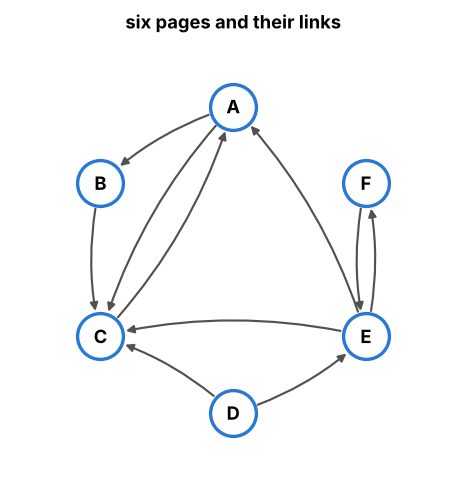

In [4]:
# ---------- plotting helper (visualisation only) ----------
def draw_graph(ax, links, pages, sizes=None, title=""):
    ang = np.linspace(0, 2 * np.pi, len(pages), endpoint=False) + np.pi / 2
    xy = {p: (np.cos(a), np.sin(a)) for p, a in zip(pages, ang)}
    s = np.full(len(pages), 900.0) if sizes is None else 400 + 3000 * np.asarray(sizes) / max(sizes)
    radius = {p: np.sqrt(s[k]) / 2 + 2 for k, p in enumerate(pages)}      # node radius in points
    for j, targets in links.items():
        for i in targets:
            ax.annotate("", xy=xy[i], xytext=xy[j],
                        arrowprops=dict(arrowstyle="-|>", color=C["muted"], lw=1.4, shrinkA=radius[j], shrinkB=radius[i],
                                        connectionstyle="arc3,rad=0.12"))
    for k, p in enumerate(pages):
        ax.scatter(*xy[p], s=s[k], color="white", edgecolor=C["blue"], linewidth=2.2, zorder=3)
        ax.text(*xy[p], p, ha="center", va="center", fontsize=12, fontweight="bold", zorder=4)
    ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.45, 1.45); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
draw_graph(ax, links, pages, title="six pages and their links")
plt.tight_layout(); plt.show()

---
## 3 · Iterating to the steady state 🔁

### 3.1 · One step by hand
Start with $r^{(0)}=(1,1,1,1,1,1)$. Page A has two links, so it sends $\tfrac12$ to B and $\tfrac12$ to C. Page E has three links and sends $\tfrac13$ each to A, C, F. Nobody links to D, so D receives nothing.

In [5]:
r0 = np.ones(N)                                  # notes: "assign influence = 1 for all"
r1 = M @ r0                                      # one redistribution
for p in pages:
    print(f"r1[{p}] = {r1[pos_of[p]]:.3f}")
print("total influence:", r0.sum(), "→", r1.sum())

r1[A] = 1.333
r1[B] = 0.500
r1[C] = 2.333
r1[D] = 0.000
r1[E] = 1.500
r1[F] = 0.333
total influence: 6.0 → 6.0


### 3.2 · Repeat until nothing changes
The loop keeps applying $r\leftarrow Mr$ and records every vector. It stops when the total change $\sum_i\lvert r^{(t+1)}_i-r^{(t)}_i\rvert$ falls below a small tolerance – the **steady state**.

In [6]:
def power_iteration(M, r0, tol=1e-10, max_iter=200):
    """Apply r <- M r until the L1 change is below tol. Returns all iterates and the changes."""
    history, changes = [r0], []
    r = r0
    for _ in range(max_iter):
        r_new = M @ r
        changes.append(np.abs(r_new - r).sum())
        history.append(r_new)
        r = r_new
        if changes[-1] < tol:
            break
    return np.array(history), np.array(changes)

hist, changes = power_iteration(M, np.ones(N))
print(f"converged after {len(changes)} iterations")
print("steady-state ranks:", {p: round(float(hist[-1][pos_of[p]]), 3) for p in pages})

converged after 72 iterations
steady-state ranks: {'A': 2.4, 'B': 1.2, 'C': 2.4, 'D': 0.0, 'E': 0.0, 'F': 0.0}


📊 **Plot:** each page's rank over the iterations (left) and the size of the change per iteration on a log scale (right) – a straight line means the error shrinks by the same factor every step.

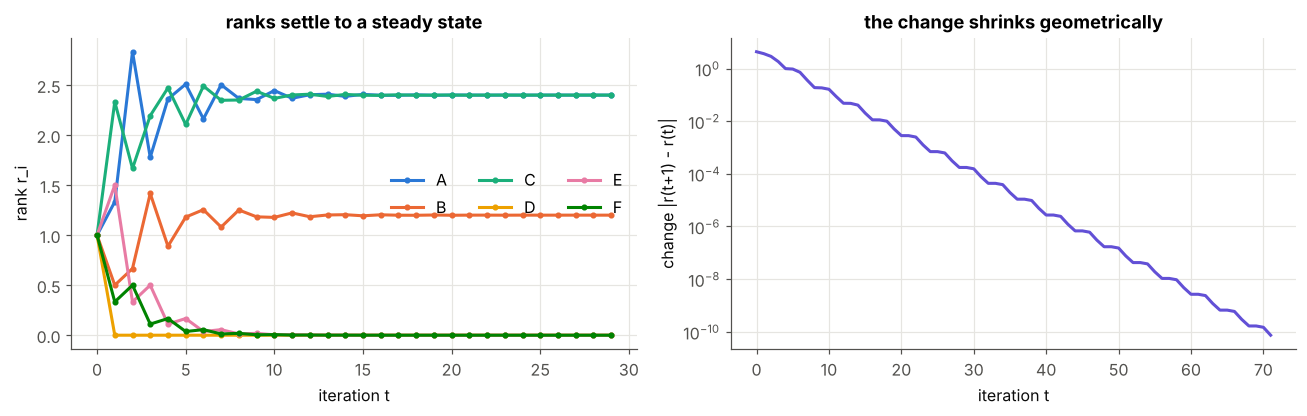

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.9))
for k, p in enumerate(pages):
    axs[0].plot(hist[:30, k], "o-", ms=3, label=p)
axs[0].set_xlabel("iteration t"); axs[0].set_ylabel("rank r_i"); axs[0].set_title("ranks settle to a steady state"); axs[0].legend(ncol=3)
axs[1].semilogy(changes, color=C["violet"])
axs[1].set_xlabel("iteration t"); axs[1].set_ylabel("change |r(t+1) - r(t)|"); axs[1].set_title("the change shrinks geometrically")
plt.tight_layout(); plt.show()

### 3.3 · The steady state is an eigenvector
At the steady state $r=Mr$, i.e. $r$ is an **eigenvector** of $M$ with **eigenvalue 1**. We can check our iterative answer against NumPy's eigen-solver (after scaling both to the same total).

In [8]:
eigvals, eigvecs = np.linalg.eig(M)
k1 = np.argmin(np.abs(eigvals - 1))                    # the eigenvalue closest to 1
v1 = np.real(eigvecs[:, k1])
v1 = v1 / v1.sum() * hist[-1].sum()                    # same total influence as our r
print("eigenvalue:", np.round(eigvals[k1].real, 6))
print("eigenvector :", np.round(v1, 4))
print("iteration   :", np.round(hist[-1], 4))

eigenvalue: 1.0
eigenvector : [ 2.4  1.2  2.4 -0.  -0.  -0. ]
iteration   : [2.4 1.2 2.4 0.  0.  0. ]


Same answer. Iterating is how you find it in practice: for the real web ($N$ in the billions) an eigen-solver is impossible, but $r\leftarrow Mr$ is just a sparse matrix-vector product.

**But look at the result:** D got 0, and all influence piled up in a few pages. That leads to the notes' *"under certain conditions"*.

---
## 4 · The "certain conditions" ⚠️

Two things can stop the simple iteration from giving a sensible steady state:

| Problem | What happens | Example |
|---|---|---|
| **Dangling page** (no outgoing links) | its influence disappears; the total shrinks to 0 | a PDF with no links |
| **Cycles / traps** | influence circulates forever and never settles, or gets stuck inside a closed group | A ↔ B only |

### 4.1 · A dangling page leaks influence

In [9]:
links_dangling = {"A": ["B", "C"], "B": ["C"], "C": ["A", "D"], "D": []}    # D links nowhere
pages_d = sorted(links_dangling)
M_d = link_matrix(links_dangling, pages_d)
hist_d, _ = power_iteration(M_d, np.ones(4), max_iter=40)
print("column sums:", M_d.sum(axis=0), "  ← D's column is all zero")
print("total influence after 0, 5, 20, 40 steps:", [round(float(hist_d[t].sum()), 4) for t in (0, 5, 20, 40)])

column sums: [1. 1. 1. 0.]   ← D's column is all zero
total influence after 0, 5, 20, 40 steps: [4.0, 1.0625, 0.0173, 0.0001]


### 4.2 · A cycle never settles

In [10]:
links_cycle = {"A": ["B"], "B": ["A"]}
M_c = link_matrix(links_cycle, ["A", "B"])
hist_c, _ = power_iteration(M_c, np.array([2.0, 0.0]), max_iter=12)
print("ranks of A over time:", hist_c[:, 0])

ranks of A over time: [2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2.]


### 4.3 · The fix: damping (the "random surfer")
Imagine a surfer who, at every step, follows a random link with probability $\alpha$ (typically 0.85) and **jumps to a random page** with probability $1-\alpha$; a surfer on a dangling page always jumps. In formulas:

$$r^{(t+1)}=\alpha\left(M\ r^{(t)}+\frac{\text{lost}^{(t)}}{N}\mathbf 1\right)+(1-\alpha)\frac{\sum_i r_i^{(t)}}{N}\ \mathbf 1$$

where $\text{lost}^{(t)}$ = the influence sitting on dangling pages, spread evenly. Every page now gets *some* influence, nothing leaks, and the random jumps break cycles – these are the conditions under which a unique steady state always exists.

In [11]:
def pagerank(M, alpha=0.85, tol=1e-10, max_iter=500, r0=None):
    """Damped PageRank by power iteration. Dangling columns are spread evenly."""
    N = M.shape[0]
    dangling = M.sum(axis=0) == 0                          # pages with no out-links
    r = np.ones(N) if r0 is None else np.asarray(r0, float)
    history = [r]
    for _ in range(max_iter):
        lost = r[dangling].sum()                           # influence sitting on dangling pages
        r_new = alpha * (M @ r + lost / N) + (1 - alpha) * r.sum() / N
        history.append(r_new)
        if np.abs(r_new - r).sum() < tol:
            break
        r = r_new
    return np.array(history)

**Run all three webs with damping:**

In [12]:
pr_main = pagerank(M)
pr_dang = pagerank(M_d)
pr_cycle = pagerank(M_c)
print("six-page web :", {p: round(float(pr_main[-1][pos_of[p]]), 3) for p in pages}, " total", pr_main[-1].sum().round(3))
print("dangling web : total influence stays", pr_dang[-1].sum().round(3))
print("A↔B cycle    :", pr_cycle[-1].round(3), "after", len(pr_cycle) - 1, "iterations")

six-page web : {'A': 2.037, 'B': 1.016, 'C': 2.07, 'D': 0.15, 'E': 0.45, 'F': 0.277}  total 6.0
dangling web : total influence stays 4.0
A↔B cycle    : [1. 1.] after 1 iterations


📊 **Plot:** (left) the A↔B cycle oscillates without damping and settles with it; (right) the six-page web drawn with node size ∝ damped PageRank.

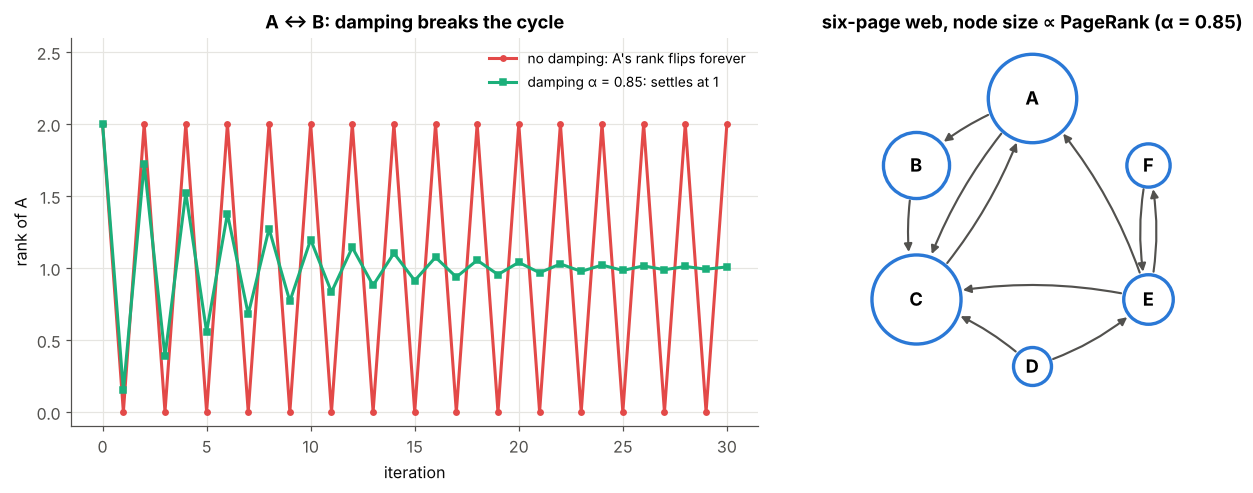

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
hist_c30, _ = power_iteration(M_c, np.array([2.0, 0.0]), max_iter=30)
cyc_damped = pagerank(M_c, max_iter=30, tol=0, r0=[2.0, 0.0])     # same start as the undamped run
axs[0].plot(hist_c30[:, 0], "o-", ms=3.5, color=C["red"], label="no damping: A's rank flips forever")
axs[0].plot(cyc_damped[:, 0], "s-", ms=3.5, color=C["aqua"], label="damping α = 0.85: settles at 1")
axs[0].set_ylim(-0.1, 2.6); axs[0].legend(fontsize=9, loc="upper right")
axs[0].set_xlabel("iteration"); axs[0].set_ylabel("rank of A"); axs[0].set_title("A ↔ B: damping breaks the cycle")
draw_graph(axs[1], links, pages, sizes=pr_main[-1], title="six-page web, node size ∝ PageRank (α = 0.85)")
plt.tight_layout(); plt.show()

---
## 5 · The same idea on words 🔤

Back to the notes' point: *"same solution for this."* A word's meaning is defined by its neighbours' meanings. We can solve such a recursive definition the PageRank way:

1. Fix the meaning of a few **seed** words (we know *mango* is fruit, *water* is a drink, *loan* is money, *river* is a river).
2. Give every other word a neutral guess (equal parts of everything).
3. Repeatedly set each non-seed word's meaning to the **weighted average of its neighbours' meanings**, weighted by co-occurrence counts.

Each "meaning" here is a vector of 4 numbers: how much fruit / drink / money / river.

### 5.1 · The corpus and the co-occurrence graph
Same toy corpus and co-occurrence counts as notebook 02.

In [14]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Step A – vocabulary and co-occurrence counts** (window 3, as in notebook 02):

In [15]:
sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)

X = np.zeros((n, n))
for s in sentences:
    ids = [index[w] for w in s]
    for p, i in enumerate(ids):
        for q in range(max(0, p - 3), min(len(ids), p + 4)):
            if q != p:
                X[i, ids[q]] += 1
print("n =", n, "words")

n = 75 words


**Step B – the edge weights.** Raw counts would let hub words like *the*, *i*, *like* connect everything to everything (they are the "dangling-page / trap" problem of this graph: meaning would just leak through them and wash out). So, as in notebook 02, we weight edges by **PPMI** instead, which is ≈0 for those hubs. Each row is then normalised to sum to 1: row $i$ of `T` says how much each neighbour counts towards word $i$'s meaning – the word version of the link matrix (rows instead of columns).

In [16]:
P_joint = X / X.sum()
with np.errstate(divide="ignore"):
    PPMI = np.maximum(np.log(P_joint / (P_joint.sum(1, keepdims=True) * P_joint.sum(0, keepdims=True))), 0)
T = PPMI / PPMI.sum(axis=1, keepdims=True)        # T[i, j] = weight of neighbour j in word i's meaning
print("each row of T sums to 1:", np.allclose(T.sum(axis=1), 1), "   weight of 'the' in king's row:", T[index["king"], index["the"]].round(3))

each row of T sums to 1: True    weight of 'the' in king's row: 0.015


### 5.2 · Seeds and the starting guess

In [17]:
topics = ["fruit", "drink", "money", "river"]
seeds = {"mango": "fruit", "water": "drink", "loan": "money", "river": "river"}
F = np.full((n, len(topics)), 1 / len(topics))    # every word starts as 25% of each topic
for w, t in seeds.items():
    F[index[w]] = np.eye(len(topics))[topics.index(t)]   # seeds are 100% their topic
seed_rows = np.array([index[w] for w in seeds])
print("starting meaning of 'apple':", F[index["apple"]], "  of 'mango':", F[index["mango"]])

starting meaning of 'apple': [0.25 0.25 0.25 0.25]   of 'mango': [1. 0. 0. 0.]


### 5.3 · Iterate: meaning ← average of neighbours' meaning
One step is `T @ F` (every word becomes the weighted average of its neighbours); then the seeds are reset to their known values. We stop when the meanings stop changing.

In [18]:
def propagate(T, F0, seed_rows, iters=300):
    F = F0.copy()
    seed_values = F0[seed_rows].copy()
    history = [F.copy()]
    for _ in range(iters):
        F = T @ F                                  # average of neighbours' meanings
        F[seed_rows] = seed_values                 # keep what we know
        history.append(F.copy())
    return np.array(history)

hist_words = propagate(T, F, seed_rows)
change = np.abs(np.diff(hist_words, axis=0)).sum(axis=(1, 2))
print("total change per iteration (first 6):", change[:6].round(3), " … last:", change[-1].round(8))

total change per iteration (first 6): [3.468 3.305 2.488 2.094 1.68  1.384]  … last: 0.00147393


**Read off the learned meanings** of words we never labelled:

In [19]:
check = ["apple", "banana", "tea", "coffee", "interest", "rupees", "fish", "boat", "bank", "sweet", "swim", "king"]
final = hist_words[-1]
for w in check:
    f = final[index[w]]
    verdict = topics[f.argmax()] if f.max() - f.min() > 0.05 else "no clear topic"
    print(f"{w:<9} " + "  ".join(f"{t} {v:4.0%}" for t, v in zip(topics, f)) + f"   → {verdict}")

apple     fruit  61%  drink  13%  money  13%  river  13%   → fruit
banana    fruit  61%  drink  13%  money  13%  river  13%   → fruit
tea       fruit  14%  drink  61%  money  13%  river  13%   → drink
coffee    fruit  13%  drink  61%  money  13%  river  13%   → drink
interest  fruit  14%  drink  14%  money  49%  river  24%   → money
rupees    fruit  12%  drink  11%  money  56%  river  21%   → money
fish      fruit  14%  drink  14%  money  23%  river  49%   → river
boat      fruit  14%  drink  14%  money  24%  river  49%   → river
bank      fruit  11%  drink  11%  money  40%  river  37%   → money
sweet     fruit  67%  drink  11%  money  11%  river  11%   → fruit
swim      fruit  12%  drink  12%  money  21%  river  56%   → river
king      fruit  25%  drink  25%  money  25%  river  24%   → no clear topic


Words that never appear next to a seed (*apple* never meets *mango*!) still get the right topic, because meaning flows **two hops**: apple → *sweet, ripe* → mango. *king* stays neutral – no seed tells it anything, which is honest.

📊 **Plot:** the learned topic mix of each word (left) and the total change per iteration (right). *bank* comes out as a **mix of money and river** – the meaning it really has in this corpus.

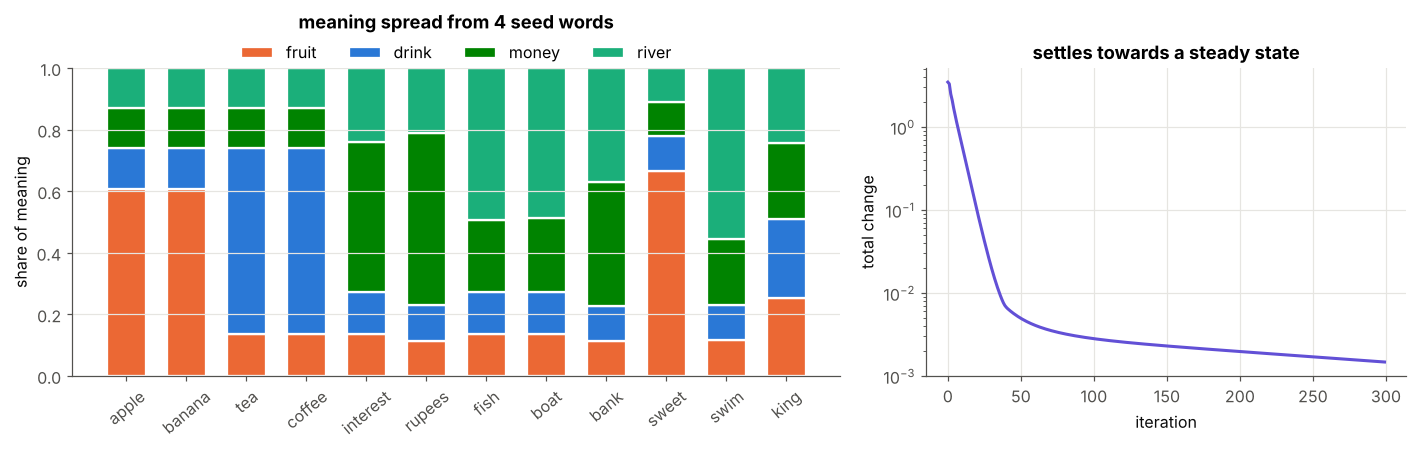

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
bottom = np.zeros(len(check))
for t_k, (t, col) in enumerate(zip(topics, [C["orange"], C["blue"], C["green"], C["aqua"]])):
    vals = np.array([final[index[w], t_k] for w in check])
    axs[0].bar(check, vals, bottom=bottom, color=col, label=t, width=0.65, edgecolor="white", linewidth=1.5)
    bottom += vals
axs[0].set_ylim(0, 1); axs[0].set_ylabel("share of meaning"); axs[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.13))
axs[0].tick_params(axis="x", rotation=40); axs[0].grid(axis="x", visible=False)
axs[0].set_title("meaning spread from 4 seed words", pad=26)
axs[1].semilogy(change + 1e-16, color=C["violet"])
axs[1].set_xlabel("iteration"); axs[1].set_ylabel("total change"); axs[1].set_title("settles towards a steady state")
plt.tight_layout(); plt.show()

**Why this matters for word2vec.** We did not solve the recursive definition with algebra; we **repeated it** until a steady state appeared. Word2vec does the same in spirit: each training step nudges a word's vector to better predict its neighbours, and after many passes the vectors settle. The difference is that word2vec learns *dense, distributed* vectors with no seeds at all – the dimensions are discovered, not given.

---
## 6 · Summary 📌

| Concept | Formula / fact |
|---|---|
| recursive definition | $r_i=\sum_{j\to i}r_j/\text{out}(j)$, i.e. $r=Mr$ |
| iterative solution | $r^{(t+1)}=Mr^{(t)}$ from $r^{(0)}=\mathbf 1$ |
| steady state | eigenvector of $M$ with eigenvalue 1 |
| conditions | dangling pages leak, cycles oscillate → damping $\alpha$ fixes both |
| for words | meaning ← weighted average of neighbours' meanings, repeated to convergence |

### ✍️ Try it yourself
1. Set $\alpha=0.5$ and $\alpha=0.99$. How do the ranks and the number of iterations change?
2. Add a link D → A. How does D's rank change? Why?
3. In section 5, remove the seed `river`. What happens to *fish* and *bank*?
4. Prove that if every column of $M$ sums to 1, then $\sum_i r^{(t+1)}_i=\sum_i r^{(t)}_i$.

**Next →** `04 - Word2Vec Model`